# 04 - Proyección de costos
Proyección de los precios de las materias primas y, a partir del modelo de relación, del costo futuro de cada equipo con intervalos de confianza.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PROCESSED = Path("../data/processed")

historico = pd.read_csv(
    DATA_PROCESSED / "historico_equipos_limpio.csv",
    parse_dates=["Date"]
)

In [2]:
mensual = historico.set_index("Date").resample("MS").mean()

print(mensual.shape)
display(mensual.head())
display(mensual.tail())

(164, 5)


,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,
2010-01-01,77.013000,547.000000,2234.325000,451.818000,945.189500
2010-02-01,74.790000,538.000000,2048.575000,444.143500,886.575000
2010-03-01,79.931304,606.630435,2204.130435,501.005217,965.705652
2010-04-01,85.753810,682.976190,2313.083333,562.120476,1025.756667
2010-05-01,76.997619,679.642857,2048.666667,558.783333,932.173333


,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,
2023-04-01,83.368947,603.885789,2336.763158,503.402105,1009.561053
2023-05-01,75.694783,550.593913,2271.586957,457.468696,964.018261
2023-06-01,74.978636,541.775909,2180.738636,449.975909,931.185455
2023-07-01,80.160000,554.357619,2152.011905,460.872381,929.810476
2023-08-01,85.104348,556.303913,2133.021739,461.035217,927.660870


In [3]:
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from sklearn.metrics import mean_absolute_percentage_error

meses_prueba = 12
entrenamiento = mensual.iloc[:-meses_prueba]
prueba = mensual.iloc[-meses_prueba:]

serie = "Price_Y"

modelo_ets = ETSModel(
    entrenamiento[serie],
    error="add",
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=12,
).fit(disp=False)
pronostico_ets = modelo_ets.forecast(meses_prueba)

pronostico_ingenuo = pd.Series(entrenamiento[serie].iloc[-1], index=prueba.index)

print(f"MAPE suavizado exponencial: {mean_absolute_percentage_error(prueba[serie], pronostico_ets):.2%}")
print(f"MAPE método ingenuo:        {mean_absolute_percentage_error(prueba[serie], pronostico_ingenuo):.2%}")

MAPE suavizado exponencial: 12.45%
MAPE método ingenuo:        6.67%


In [4]:
modelo_ets_sin_tendencia = ETSModel(
    entrenamiento[serie],
    error="add",
    trend=None,
    seasonal="add",
    seasonal_periods=12,
).fit(disp=False)
pronostico_sin_tendencia = modelo_ets_sin_tendencia.forecast(meses_prueba)

print(f"MAPE suavizado sin tendencia: {mean_absolute_percentage_error(prueba[serie], pronostico_sin_tendencia):.2%}")

MAPE suavizado sin tendencia: 6.03%


In [5]:
def evaluar_metodos(serie, datos, cortes, horizonte=12):
    """Compara los métodos de pronóstico de una serie en varias ventanas y devuelve el MAPE de cada uno."""
    resultados = []

    for corte in cortes:
        entrenamiento = datos.loc[:corte, serie]
        prueba = datos.loc[corte:, serie].iloc[1:horizonte + 1]

        pronosticos = {
            "Ingenuo": pd.Series(entrenamiento.iloc[-1], index=prueba.index),
            "ETS con tendencia": ETSModel(entrenamiento, error="add", trend="add", damped_trend=True,
                                          seasonal="add", seasonal_periods=12).fit(disp=False).forecast(horizonte),
            "ETS sin tendencia": ETSModel(entrenamiento, error="add", trend=None,
                                          seasonal="add", seasonal_periods=12).fit(disp=False).forecast(horizonte),
        }

        for metodo, pronostico in pronosticos.items():
            resultados.append({
                "serie": serie,
                "corte": corte,
                "metodo": metodo,
                "mape": mean_absolute_percentage_error(prueba, pronostico),
            })

    return pd.DataFrame(resultados)

In [6]:
cortes = ["2019-08-01", "2020-08-01", "2021-08-01", "2022-08-01"]

resultados = pd.concat([
    evaluar_metodos(serie, mensual, cortes)
    for serie in ["Price_X", "Price_Y", "Price_Z"]
])

tabla_mape = resultados.pivot_table(index="serie", columns="metodo", values="mape", aggfunc="mean")
display((tabla_mape * 100).round(2))

metodo,ETS con tendencia,ETS sin tendencia,Ingenuo
serie,,,
Price_X,23.21,26.64,25.29
Price_Y,16.93,15.37,15.30
Price_Z,9.24,10.84,10.60


In [7]:
import numpy as np

def error_por_horizonte(serie, tendencia, datos, cortes, horizonte=12):
    """Calcula el error porcentual promedio para cada mes adelante (1 a horizonte)."""
    errores = []

    for corte in cortes:
        entrenamiento = datos.loc[:corte, serie]
        prueba = datos.loc[corte:, serie].iloc[1:horizonte + 1]

        modelo = ETSModel(entrenamiento, error="add", trend=tendencia, damped_trend=tendencia is not None,
                          seasonal="add", seasonal_periods=12).fit(disp=False)
        pronostico = modelo.forecast(horizonte)

        errores.append(np.abs(prueba.values - pronostico.values) / prueba.values * 100)

    return pd.Series(np.mean(errores, axis=0), index=range(1, horizonte + 1))

,Price_X,Price_Y,Price_Z
1,7.5,3.4,4.0
2,9.2,4.2,5.0
3,9.0,8.9,3.4
4,11.7,10.4,4.4
5,15.7,13.0,6.4
6,14.7,11.6,9.1
7,38.0,13.2,13.3
8,48.0,19.5,15.2
9,41.7,24.7,12.6
10,33.7,22.4,11.7


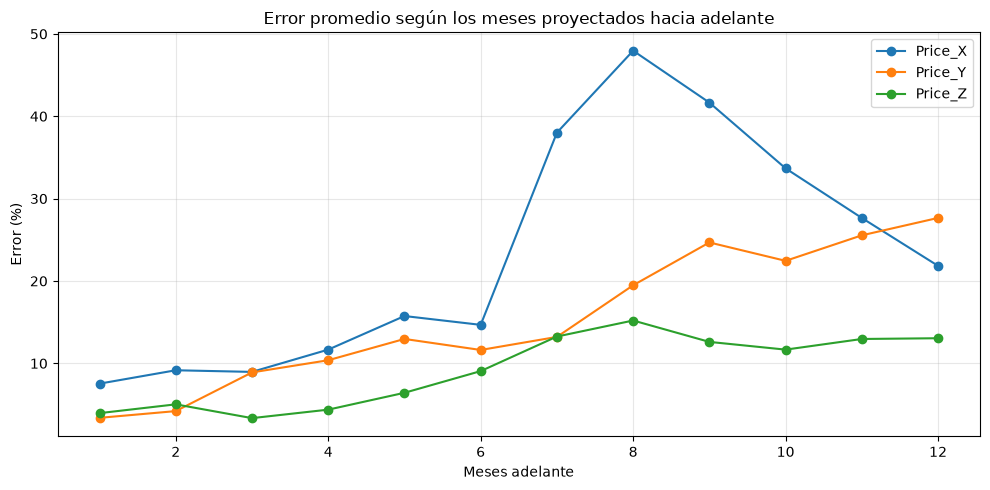

In [8]:
metodo_elegido = {"Price_X": "add", "Price_Y": None, "Price_Z": "add"}

errores_horizonte = pd.DataFrame({
    serie: error_por_horizonte(serie, tendencia, mensual, cortes)
    for serie, tendencia in metodo_elegido.items()
})

display(errores_horizonte.round(1))

errores_horizonte.plot(marker="o", figsize=(10, 5))
plt.title("Error promedio según los meses proyectados hacia adelante")
plt.xlabel("Meses adelante")
plt.ylabel("Error (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figures/05_error_por_horizonte.png", dpi=150)
plt.show()

## Horizonte de predicción

1. El error crece a medida que se proyectan más meses. Hasta el mes 6 se mantiene controlado (máximo cerca de 15%), pero desde el mes 7 se dispara, sobre todo en el precio de X.
2. El mayor error de X (38% y 48%) ocurre en los meses 7 y 8 de la ventana que aprendió hasta agosto de 2019, es decir, en marzo y abril de 2020. Coincide con la pandemia del COVID-19, cuando el petróleo WTI llegó a negociarse a precios negativos el 20 de abril de 2020 ([EIA](https://www.eia.gov/todayinEnergy/detail.php?id=46336)).
3. Eventos como este no se pueden prever con datos históricos. Por eso se define un horizonte de 6 meses y se recomienda actualizar la proyección cada mes con los datos nuevos.